# Tugas UTS: Linear Regression & Logistic Regression
**Mata Kuliah:** Machine Learning

Tugas ini menguji pemahaman Anda tentang materi **Simple Regression** (`simple_regression/regression_1.ipynb`) dan **Simple Classification** (`simple_classification/classification_1.ipynb`). Anda akan menerapkan algoritma yang sama pada **dataset baru**, lalu mengembangkannya dengan evaluasi dan eksperimen tambahan.

**Identitas Mahasiswa**
- Nama  : Nur Aisyah
- NIM   : 241011402656
- Kelas : Reg B

## 📌 Ketentuan Pengerjaan

1. Kerjakan semua soal di notebook ini pada sel kode / sel markdown yang telah disediakan.
2. **Model dan metrik evaluasi wajib diimplementasikan sendiri** dengan NumPy, seperti pada materi (`train_test_split`, `LinearRegression`, `LinearRegressionGD`, `LogisticRegression`, `accuracy_score`, `confusion_matrix`). Anda boleh menyalin implementasi dari materi.
   - Library yang boleh dipakai: `numpy`, `pandas`, `matplotlib`.
   - `scikit-learn` **tidak boleh** dipakai untuk model dan metrik, kecuali pada soal bonus untuk membandingkan hasil.
3. **`random_state` = 2 digit terakhir NIM Anda** (contoh: NIM `...0347` → `random_state=47`; jika `00`, gunakan `100`). Karena itu, setiap mahasiswa akan mendapat hasil angka yang berbeda.
4. Setiap soal yang meminta **penjelasan/analisis** dijawab dengan kalimat Anda sendiri pada sel markdown, dan harus merujuk ke angka/grafik hasil Anda.
5. Notebook harus **sudah dijalankan** (*Run All*) sehingga semua output dan grafik terlihat saat dibuka di GitHub.

## 📂 Dataset
Dataset disediakan di folder ini:

| File | Kolom | Keterangan |
|---|---|---|
| `Ads_Data.csv` | `BiayaIklan`, `Penjualan` | Biaya iklan per bulan (juta Rp) dan penjualan per bulan (juta Rp), 40 data |
| `Email_Data.csv` | `JumlahLink`, `KataPromo`, `Spam` | Jumlah link dan jumlah kata promosi dalam sebuah email, serta label Spam (1) / Bukan Spam (0), 60 data |

## 📤 Cara Pengumpulan

1. Buat **repositori baru** di akun GitHub Anda masing-masing dengan nama: `uts-machine-learning-<NIM>` (contoh: `uts-machine-learning-20230801047`).
2. Atur repositori menjadi **Public**.
3. Struktur repositori minimal:
   ```
   uts-machine-learning-<NIM>/
   ├── README.md            # Nama, NIM, Kelas, dan ringkasan hasil (R², akurasi, dll)
   ├── tugas_UTS.ipynb      # notebook ini, sudah dijalankan lengkap dengan output
   ├── Ads_Data.csv
   └── Email_Data.csv
   ```
4. Kumpulkan **link repositori GitHub** di halaman **UTS pada Mentari**.
5. Batas waktu pengumpulan (hari terakhir periode UTS):

| Kelas | Batas Pengumpulan |
|---|---|
| **Reg B** | **Jumat, 23 Oktober 2026, pukul 23:59 WIB** |
| **Reg C** | **Sabtu, 24 Oktober 2026, pukul 23:59 WIB** |

> ⚠️ Yang dinilai adalah **commit terakhir sebelum batas waktu**. Commit setelah batas waktu tidak akan dinilai. Pastikan link yang dikumpulkan bisa dibuka (repositori tidak *private*).

## 🧮 Penilaian

| Bagian | Bobot |
|---|---|
| Bagian A – Linear Regression | 35% |
| Bagian B – Logistic Regression | 40% |
| Bagian C – Pemahaman Konsep | 15% |
| Kerapihan repositori, README, dan notebook (output lengkap, kode rapi & diberi komentar) | 10% |
| Bonus – Perbandingan dengan scikit-learn | +5 |

In [43]:
# import Library
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

RANDOM_STATE = 56

In [44]:
# Salin fungsi train_test_split dari materi di sini

def train_test_split(X, y, test_size=0.2, random_state=56):
    np.random.seed(random_state)

    indeks = np.random.permutation(len(X))
    jumlah_test = int(len(X) * test_size)

    indeks_test = indeks[:jumlah_test]
    indeks_train = indeks[jumlah_test:]

    X_train = X[indeks_train]
    X_test = X[indeks_test]
    y_train = y[indeks_train]
    y_test = y[indeks_test]

    return X_train, X_test, y_train, y_test

---
# Bagian A – Linear Regression (35%)

Sebuah toko online ingin mengetahui pengaruh **biaya iklan** terhadap **penjualan** setiap bulan. Gunakan dataset `Ads_Data.csv`.

### Soal A1 – Load & Visualisasi Data
1. Baca `Ads_Data.csv` menggunakan pandas dan tampilkan 5 data pertama serta jumlah baris datanya.
2. Pisahkan `X` (`BiayaIklan`) dan `y` (`Penjualan`). Pastikan `X` berbentuk 2 dimensi `(n, 1)`.
3. Buat *scatter plot* `BiayaIklan` vs `Penjualan` (lengkap dengan judul dan label sumbu).

,BiayaIklan,Penjualan
0,0.8,34.3
1,0.9,38.8
2,1.0,33.2
3,1.3,36.0
4,1.7,51.3


Jumlah baris dan kolom: (40, 2)
Shape X: (40, 1)
Shape y: (40,)


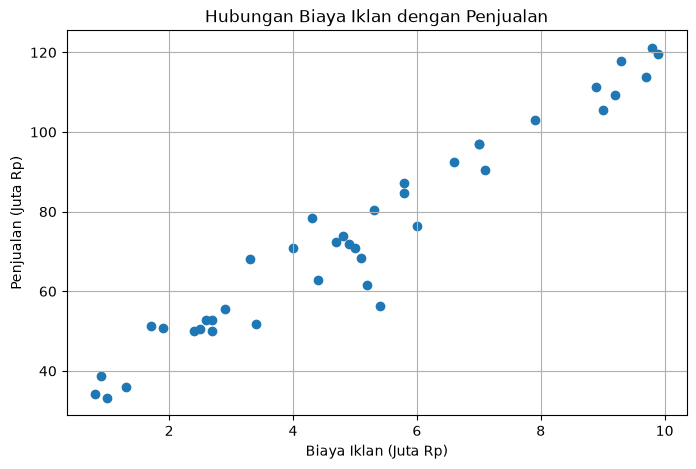

In [45]:
# Jawaban A1


# Membaca dataset iklan
data_iklan = pd.read_csv("Ads_Data.csv")

# Menampilkan 5 data pertama
display(data_iklan.head())

# Menampilkan jumlah baris dan kolom
print("Jumlah baris dan kolom:", data_iklan.shape)

# Memisahkan variabel X dan y
X = data_iklan[["BiayaIklan"]].values
y = data_iklan["Penjualan"].values

print("Shape X:", X.shape)
print("Shape y:", y.shape)

# Visualisasi data
plt.figure(figsize=(8, 5))
plt.scatter(X[:, 0], y)
plt.title("Hubungan Biaya Iklan dengan Penjualan")
plt.xlabel("Biaya Iklan (Juta Rp)")
plt.ylabel("Penjualan (Juta Rp)")
plt.grid(True)
plt.show()




### Soal A2 – Split Data
Bagi data menjadi data training dan testing dengan `test_size=0.2` dan `random_state=RANDOM_STATE`. Tampilkan *shape* dari `X_train`, `X_test`, `y_train`, `y_test`.

In [46]:
# Jawaban A2


# Membagi data dengan 80% training dan 20% testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Menampilkan ukuran setiap data
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("y_train:", y_train.shape)
print("y_test :", y_test.shape)


X_train: (32, 1)
X_test : (8, 1)
y_train: (32,)
y_test : (8,)


### Soal A3 – Training dengan Normal Equation
1. Latih model `LinearRegression` (normal equation, seperti di materi) menggunakan data training.
2. Tampilkan nilai **intercept** ($b$) dan **koefisien** ($m$), lalu tuliskan persamaan garis regresinya: $\hat{y} = b + mX$.
3. **Interpretasikan** arti nilai $m$ dalam konteks kasus ini (misal: "setiap kenaikan biaya iklan 1 juta Rp, penjualan naik sebesar ...").

In [47]:
# Jawaban A3


# Menambahkan kolom 1 untuk menghitung intercept
X_train_b = np.c_[np.ones((len(X_train), 1)), X_train]

# Menghitung parameter dengan Normal Equation
theta = np.linalg.pinv(X_train_b.T @ X_train_b) @ X_train_b.T @ y_train

# Mengambil nilai intercept dan koefisien
intercept = theta[0]
koefisien = theta[1]

print("Intercept (b):", intercept)
print("Koefisien (m):", koefisien)

print(
    f"Persamaan regresi: y = {intercept:.4f} "
    f"+ ({koefisien:.4f} * X)"
)


Intercept (b): 28.54048318753459
Koefisien (m): 8.98505558593031
Persamaan regresi: y = 28.5405 + (8.9851 * X)


**Jawaban A3 (interpretasi):**

Berdasarkan hasil perhitungan, model Linear Regression menghasilkan persamaan yang menghubungkan biaya iklan dengan penjualan. Intercept merupakan nilai prediksi penjualan ketika biaya iklan bernilai nol, sedangkan koefisien menunjukkan perubahan penjualan untuk setiap kenaikan satu unit biaya iklan. Jika koefisien bernilai positif, peningkatan biaya iklan cenderung diikuti peningkatan penjualan berdasarkan model.

### Soal A4 – Evaluasi Model
Pada materi belum ada evaluasi untuk model regresi. **Implementasikan sendiri** fungsi-fungsi berikut menggunakan NumPy:

$$
MAE = \frac{1}{n}\sum_{i=1}^{n}|y_i - \hat{y}_i| \qquad
MSE = \frac{1}{n}\sum_{i=1}^{n}(y_i - \hat{y}_i)^2 \qquad
RMSE = \sqrt{MSE}
$$

$$
R^2 = 1 - \frac{\sum_{i=1}^{n}(y_i - \hat{y}_i)^2}{\sum_{i=1}^{n}(y_i - \bar{y})^2}
$$

1. Hitung MAE, MSE, RMSE, dan $R^2$ pada **data training** dan **data testing**.
2. Tampilkan hasilnya dalam satu tabel (boleh pakai `pd.DataFrame`).
3. Jelaskan arti nilai RMSE dan $R^2$ yang Anda dapatkan. Apakah model ini sudah baik?

In [48]:
# Jawaban A4


# Fungsi evaluasi model regresi
def mae(y_asli, y_prediksi):
    return np.mean(np.abs(y_asli - y_prediksi))

def mse(y_asli, y_prediksi):
    return np.mean((y_asli - y_prediksi) ** 2)

def rmse(y_asli, y_prediksi):
    return np.sqrt(mse(y_asli, y_prediksi))

def r2_score_manual(y_asli, y_prediksi):
    ss_res = np.sum((y_asli - y_prediksi) ** 2)
    ss_tot = np.sum((y_asli - np.mean(y_asli)) ** 2)
    return 1 - (ss_res / ss_tot)


# Prediksi data training
y_train_pred = X_train_b @ theta

# Prediksi data testing
X_test_b = np.c_[np.ones((len(X_test), 1)), X_test]
y_test_pred = X_test_b @ theta


# Membuat tabel hasil evaluasi
hasil_evaluasi = pd.DataFrame({
    "Data": ["Training", "Testing"],
    "MAE": [
        mae(y_train, y_train_pred),
        mae(y_test, y_test_pred)
    ],
    "MSE": [
        mse(y_train, y_train_pred),
        mse(y_test, y_test_pred)
    ],
    "RMSE": [
        rmse(y_train, y_train_pred),
        rmse(y_test, y_test_pred)
    ],
    "R2": [
        r2_score_manual(y_train, y_train_pred),
        r2_score_manual(y_test, y_test_pred)
    ]
})

display(hasil_evaluasi.round(4))


,Data,MAE,MSE,RMSE,R2
0,Training,5.1345,43.2469,6.5762,0.9276
1,Testing,2.2890,8.2377,2.8701,0.9873


**Jawaban A4 (analisis):**

Evaluasi dilakukan pada data training dan testing untuk mengetahui kemampuan model dalam memprediksi penjualan. MAE, MSE, dan RMSE digunakan untuk mengukur kesalahan prediksi, sedangkan R² digunakan untuk melihat kemampuan model menjelaskan variasi penjualan. Hasil testing penting karena menunjukkan performa model pada data yang tidak digunakan selama pelatihan. Model yang baik diharapkan memiliki kesalahan relatif kecil dan performa testing yang memadai.

### Soal A5 – Gradient Descent & Learning Rate
1. Latih model `LinearRegressionGD` (dari materi) dengan `n_iterations=5000` menggunakan **3 nilai learning rate**: `0.001`, `0.02`, dan `0.1`.
2. Untuk setiap learning rate, tampilkan intercept dan koefisien akhirnya, lalu bandingkan dengan hasil normal equation (Soal A3).
3. Buat grafik **loss (MSE) vs iterasi** untuk ketiga learning rate (boleh dalam satu grafik atau *subplot*; gunakan skala log jika perlu).
4. Jelaskan apa yang terjadi pada masing-masing learning rate: mana yang **terlalu lambat**, mana yang **pas**, dan mana yang **gagal konvergen (divergen)**? Mengapa bisa terjadi?

> *Tips: jika muncul `RuntimeWarning: overflow`, itu adalah bagian dari hasil eksperimen. Jelaskan artinya.*


Learning rate: 0.001
Parameter: [25.72029987  9.44122436]
Loss akhir: 45.07172614769079

Learning rate: 0.02
Parameter: [28.54048319  8.98505559]
Loss akhir: 43.24686663505787

Learning rate: 0.1
Parameter: [nan nan]
Loss akhir tidak stabil atau divergen


c:\Users\Nur Aisyah\AppData\Local\Programs\Python\Python315\Lib\site-packages\matplotlib\scale.py:375: RuntimeWarning: overflow encountered in exp
  return np.exp(values * np.log(self.base))


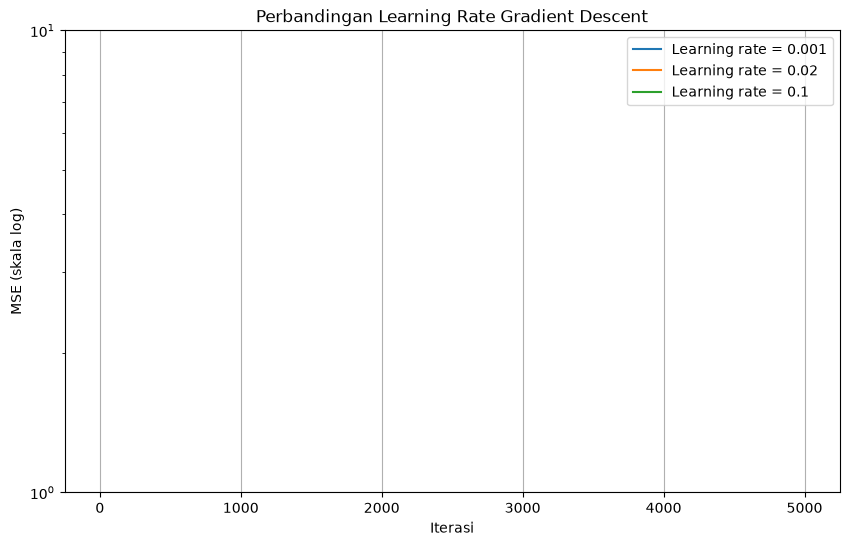

Normal Equation: [28.54048319  8.98505559]


In [49]:
# Jawaban A5


# Fungsi Linear Regression menggunakan Gradient Descent
def linear_regression_gd(X, y, learning_rate, n_iterations=5000):
    X_b = np.c_[np.ones((len(X), 1)), X]
    jumlah_data = len(y)

    theta_gd = np.zeros(X_b.shape[1])
    losses = []

    for i in range(n_iterations):
        prediksi = X_b @ theta_gd
        error = prediksi - y

        gradien = (2 / jumlah_data) * (X_b.T @ error)
        theta_gd = theta_gd - learning_rate * gradien

        loss = np.mean((X_b @ theta_gd - y) ** 2)
        losses.append(loss)

    return theta_gd, losses


# Membandingkan learning rate
learning_rates = [0.001, 0.02, 0.1]
hasil_gd = {}

for lr in learning_rates:
    with np.errstate(over="ignore", invalid="ignore"):
        theta_gd, losses = linear_regression_gd(
            X_train, y_train,
            learning_rate=lr,
            n_iterations=5000
        )

    hasil_gd[lr] = (theta_gd, losses)

    print("\nLearning rate:", lr)
    print("Parameter:", theta_gd)

    if np.all(np.isfinite(theta_gd)):
        print("Loss akhir:", losses[-1])
    else:
        print("Loss akhir tidak stabil atau divergen")


# Membuat grafik perbandingan loss
plt.figure(figsize=(10, 6))

for lr, (_, losses) in hasil_gd.items():
    losses = np.asarray(losses, dtype=float)
    losses[~np.isfinite(losses)] = np.nan

    plt.plot(losses, label=f"Learning rate = {lr}")

plt.yscale("log")
plt.title("Perbandingan Learning Rate Gradient Descent")
plt.xlabel("Iterasi")
plt.ylabel("MSE (skala log)")
plt.legend()
plt.grid(True)
plt.show()


# Membandingkan dengan Normal Equation
print("Normal Equation:", theta)


**Jawaban A5 (analisis):**

Gradient Descent memperbarui parameter secara berulang untuk mengurangi nilai MSE. Learning rate yang kecil membuat perubahan parameter lebih lambat, sedangkan learning rate yang terlalu besar dapat menyebabkan nilai loss tidak stabil atau divergen. Oleh karena itu, learning rate perlu dipilih berdasarkan hasil percobaan. Normal Equation dapat digunakan sebagai pembanding untuk melihat parameter regresi yang diperoleh melalui perhitungan matriks.

### Soal A6 – Visualisasi & Prediksi
1. Buat grafik *scatter* data **testing** beserta **garis regresi** hasil model (Soal A3).
2. Prediksi penjualan jika biaya iklan sebesar **4.5 juta**, **7 juta**, dan **12 juta**.
3. Prediksi untuk 12 juta berada **di luar rentang data** (ekstrapolasi). Menurut Anda, seberapa bisa dipercaya hasil prediksi tersebut? Jelaskan.

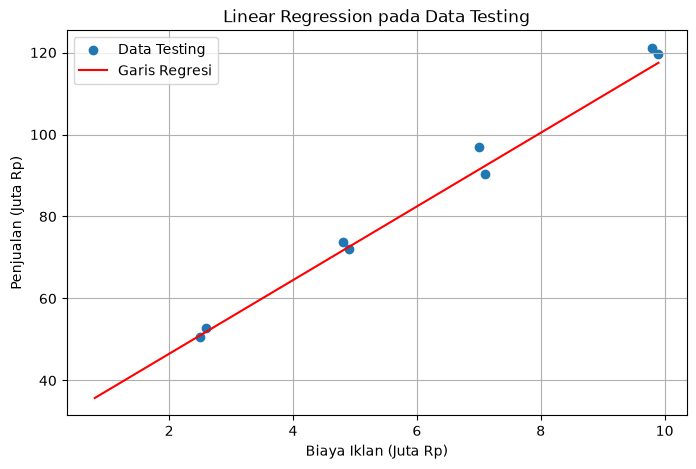

,Biaya Iklan,Prediksi Penjualan
0,4.5,68.97
1,7.0,91.44
2,12.0,136.36


In [50]:
# Jawaban A6


# Visualisasi data testing dan garis regresi
plt.figure(figsize=(8, 5))

plt.scatter(
    X_test[:, 0], y_test,
    label="Data Testing"
)

x_garis = np.linspace(
    X.min(), X.max(), 100
).reshape(-1, 1)

x_garis_b = np.c_[
    np.ones((len(x_garis), 1)),
    x_garis
]

y_garis = x_garis_b @ theta

plt.plot(
    x_garis[:, 0], y_garis,
    color="red",
    label="Garis Regresi"
)

plt.title("Linear Regression pada Data Testing")
plt.xlabel("Biaya Iklan (Juta Rp)")
plt.ylabel("Penjualan (Juta Rp)")
plt.legend()
plt.grid(True)
plt.show()


# Prediksi biaya iklan baru
biaya_baru = np.array([[4.5], [7.0], [12.0]])

biaya_baru_b = np.c_[
    np.ones((len(biaya_baru), 1)),
    biaya_baru
]

prediksi_penjualan = biaya_baru_b @ theta

hasil_prediksi = pd.DataFrame({
    "Biaya Iklan": biaya_baru[:, 0],
    "Prediksi Penjualan": prediksi_penjualan
})

display(hasil_prediksi.round(2))


**Jawaban A6 (analisis):**

Grafik menunjukkan perbandingan data testing dengan garis hasil regresi. Model digunakan untuk memprediksi penjualan berdasarkan biaya iklan sebesar 4,5 juta, 7 juta, dan 12 juta rupiah. Prediksi perlu digunakan secara hati-hati, terutama jika nilai biaya iklan berada di luar rentang data yang digunakan saat pelatihan, karena hubungan antara biaya iklan dan penjualan belum tentu selalu linear.

---
# Bagian B – Logistic Regression (40%)

Sebuah layanan email ingin membuat filter **spam** sederhana berdasarkan **jumlah link** dan **jumlah kata promosi** (misal: "gratis", "diskon", "promo") di dalam email. Gunakan dataset `Email_Data.csv`.

### Soal B1 – Load & Visualisasi Data
1. Baca `Email_Data.csv`, tampilkan 5 data pertama, dan hitung **jumlah email Spam dan Bukan Spam**.
2. Pisahkan `X` (`JumlahLink`, `KataPromo`) dan `y` (`Spam`).
3. Buat *scatter plot* `JumlahLink` vs `KataPromo` dengan warna berbeda untuk Spam dan Bukan Spam (lengkap dengan legend).

,JumlahLink,KataPromo,Spam
0,0,0,0
1,2,4,0
2,6,7,1
3,10,8,1
4,8,7,1


Ukuran dataset: (60, 3)

Jumlah kelas spam:
Spam
0    35
1    25
Name: count, dtype: int64


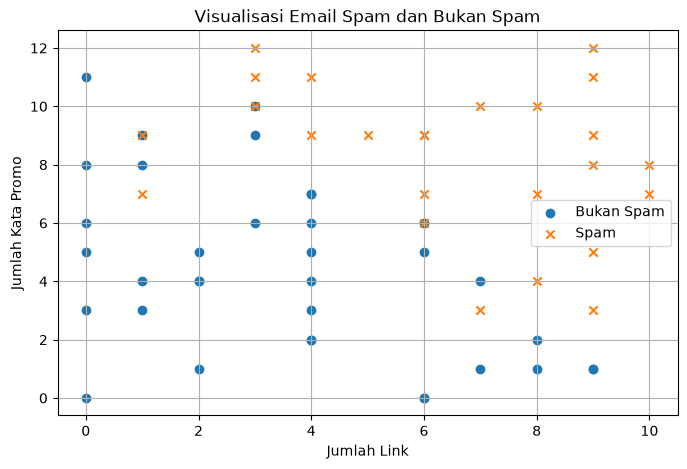

In [51]:
# Jawaban B1


# Membaca dataset email
data_email = pd.read_csv("Email_Data.csv")

# Menampilkan data
display(data_email.head())

# Melihat informasi dataset
print("Ukuran dataset:", data_email.shape)
print("\nJumlah kelas spam:")
print(data_email["Spam"].value_counts().sort_index())

# Memisahkan fitur dan target
X_email = data_email[["JumlahLink", "KataPromo"]].values
y_email = data_email["Spam"].values

# Visualisasi data
plt.figure(figsize=(8, 5))

plt.scatter(
    X_email[y_email == 0, 0],
    X_email[y_email == 0, 1],
    label="Bukan Spam"
)

plt.scatter(
    X_email[y_email == 1, 0],
    X_email[y_email == 1, 1],
    label="Spam",
    marker="x"
)

plt.title("Visualisasi Email Spam dan Bukan Spam")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(True)
plt.show()


### Soal B2 – Split Data & Training
1. Bagi data dengan `test_size=0.25` dan `random_state=RANDOM_STATE`.
2. Latih model `LogisticRegression` (gradient descent, dari materi) dengan `learning_rate=0.1` dan `n_iterations=10000`.
3. Tampilkan intercept ($b$) dan koefisien ($m_1, m_2$), lalu tuliskan persamaannya:
   $$P(\text{Spam}) = \sigma(b + m_1 \cdot \text{JumlahLink} + m_2 \cdot \text{KataPromo})$$
4. Buat grafik **log loss vs iterasi**. Apakah loss sudah turun dan stabil?

Data training: (45, 2)
Data testing: (15, 2)
Parameter model: [-9.06144394  0.81712529  0.80408304]


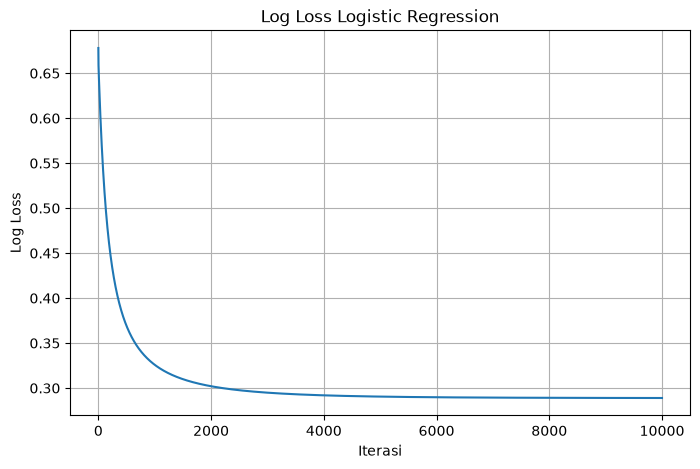

In [52]:
# Jawaban B2


# Fungsi sigmoid
def sigmoid(z):
    z = np.clip(z, -500, 500)
    return 1 / (1 + np.exp(-z))


# Fungsi Logistic Regression menggunakan Gradient Descent
def logistic_regression_gd(
    X, y, learning_rate=0.1, n_iterations=10000
):
    X_b = np.c_[np.ones((len(X), 1)), X]
    jumlah_data = len(y)

    theta_log = np.zeros(X_b.shape[1])
    losses = []

    for i in range(n_iterations):
        z = X_b @ theta_log
        probabilitas = sigmoid(z)

        gradien = X_b.T @ (probabilitas - y) / jumlah_data
        theta_log = theta_log - learning_rate * gradien

        p = np.clip(
            sigmoid(X_b @ theta_log),
            1e-15, 1 - 1e-15
        )

        loss = -np.mean(
            y * np.log(p) + (1 - y) * np.log(1 - p)
        )
        losses.append(loss)

    return theta_log, losses


# Membagi data email: 75% training, 25% testing
X_train_email, X_test_email, y_train_email, y_test_email = (
    train_test_split(
        X_email, y_email,
        test_size=0.25,
        random_state=RANDOM_STATE
    )
)

print("Data training:", X_train_email.shape)
print("Data testing:", X_test_email.shape)

# Melatih model
theta_log, log_losses = logistic_regression_gd(
    X_train_email,
    y_train_email,
    learning_rate=0.1,
    n_iterations=10000
)

print("Parameter model:", theta_log)

# Grafik log loss
plt.figure(figsize=(8, 5))
plt.plot(log_losses)
plt.title("Log Loss Logistic Regression")
plt.xlabel("Iterasi")
plt.ylabel("Log Loss")
plt.grid(True)
plt.show()


**Jawaban B2 (analisis):**

Logistic Regression digunakan untuk memprediksi probabilitas email termasuk spam berdasarkan jumlah link dan jumlah kata promosi. Proses pelatihan menggunakan Gradient Descent untuk memperbarui parameter model. Grafik log loss digunakan untuk melihat perubahan kesalahan selama pelatihan. Nilai loss yang menurun dan stabil menunjukkan bahwa model semakin menyesuaikan parameter terhadap data training.

### Soal B3 – Evaluasi Model
Selain `accuracy_score` dan `confusion_matrix` dari materi, **implementasikan sendiri** fungsi berikut:

$$
Precision = \frac{TP}{TP + FP} \qquad
Recall = \frac{TP}{TP + FN} \qquad
F1 = 2 \cdot \frac{Precision \cdot Recall}{Precision + Recall}
$$

1. Hitung accuracy, confusion matrix, precision, recall, dan F1-score pada **data testing**.
2. Jelaskan arti nilai **FP** (*false positive*) dan **FN** (*false negative*) pada kasus filter spam. Kesalahan mana yang menurut Anda **lebih merugikan pengguna email**? Mengapa?

In [53]:
# Jawaban B3


# Menghitung probabilitas prediksi
def predict_proba_manual(X, theta):
    X_b = np.c_[np.ones((len(X), 1)), X]
    return sigmoid(X_b @ theta)


# Mengubah probabilitas menjadi kelas
def predict_manual(X, theta, threshold=0.5):
    probabilitas = predict_proba_manual(X, theta)
    return (probabilitas >= threshold).astype(int)


# Confusion matrix: [[TN, FP], [FN, TP]]
def confusion_matrix_manual(y_asli, y_prediksi):
    tn = np.sum((y_asli == 0) & (y_prediksi == 0))
    fp = np.sum((y_asli == 0) & (y_prediksi == 1))
    fn = np.sum((y_asli == 1) & (y_prediksi == 0))
    tp = np.sum((y_asli == 1) & (y_prediksi == 1))

    return np.array([[tn, fp], [fn, tp]])


# Menghitung metrik evaluasi
def classification_metrics(y_asli, y_prediksi):
    cm = confusion_matrix_manual(y_asli, y_prediksi)
    tn, fp = cm[0]
    fn, tp = cm[1]

    accuracy = (tp + tn) / len(y_asli)
    precision = tp / (tp + fp) if tp + fp > 0 else 0
    recall = tp / (tp + fn) if tp + fn > 0 else 0
    f1 = (
        2 * precision * recall / (precision + recall)
        if precision + recall > 0 else 0
    )

    return accuracy, precision, recall, f1, cm


# Evaluasi data testing
y_test_pred = predict_manual(
    X_test_email, theta_log, threshold=0.5
)

accuracy, precision, recall, f1, cm = classification_metrics(
    y_test_email, y_test_pred
)

print("Confusion Matrix:")
print(cm)

print("\nAccuracy :", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall   :", round(recall, 4))
print("F1-score :", round(f1, 4))

print("\nTN:", cm[0, 0])
print("FP:", cm[0, 1])
print("FN:", cm[1, 0])
print("TP:", cm[1, 1])


Confusion Matrix:
[[10  1]
 [ 0  4]]

Accuracy : 0.9333
Precision: 0.8
Recall   : 1.0
F1-score : 0.8889

TN: 10
FP: 1
FN: 0
TP: 4


**Jawaban B3 (analisis):**

Accuracy menunjukkan persentase prediksi yang benar. Precision menunjukkan ketepatan prediksi kelas spam, sedangkan recall menunjukkan seberapa banyak email spam yang berhasil terdeteksi. F1-score merupakan rata-rata harmonik precision dan recall. False Positive berarti email normal dianggap spam, sedangkan False Negative berarti email spam dianggap normal. Semua metrik perlu diperhatikan untuk mengetahui kelebihan dan kekurangan model.

### Soal B4 – Decision Boundary
1. Hitung persamaan **decision boundary** (garis saat probabilitas = 0.5):
   $$b + m_1 x_1 + m_2 x_2 = 0 \;\Rightarrow\; x_2 = -\frac{b + m_1 x_1}{m_2}$$
2. Buat visualisasi data **testing** beserta *background* probabilitas (`contourf`) dan garis decision boundary, seperti di materi.
3. Tunjukkan (beri tanda/penjelasan) data testing mana saja yang **salah diklasifikasikan**.

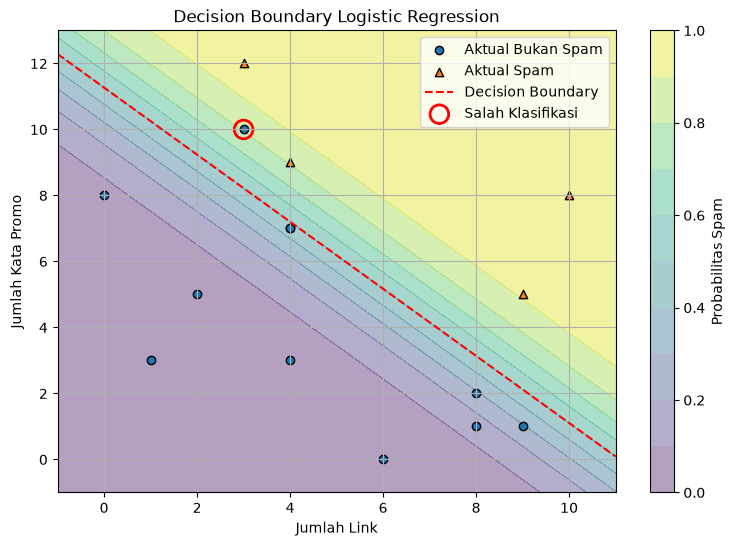

,JumlahLink,KataPromo,Spam_Aktual,Spam_Prediksi
0,3,10,0,1


In [54]:
# Jawaban B4


# Menentukan batas grafik
x1_min = X_email[:, 0].min() - 1
x1_max = X_email[:, 0].max() + 1
x2_min = X_email[:, 1].min() - 1
x2_max = X_email[:, 1].max() + 1

# Membuat grid
xx, yy = np.meshgrid(
    np.linspace(x1_min, x1_max, 200),
    np.linspace(x2_min, x2_max, 200)
)

grid = np.c_[xx.ravel(), yy.ravel()]

prob_grid = predict_proba_manual(
    grid, theta_log
).reshape(xx.shape)

# Menghitung prediksi testing
y_test_pred = predict_manual(
    X_test_email, theta_log, threshold=0.5
)

plt.figure(figsize=(9, 6))

plt.contourf(
    xx, yy, prob_grid,
    levels=np.linspace(0, 1, 11),
    alpha=0.4
)

plt.colorbar(label="Probabilitas Spam")

plt.scatter(
    X_test_email[y_test_email == 0, 0],
    X_test_email[y_test_email == 0, 1],
    label="Aktual Bukan Spam",
    edgecolors="black"
)

plt.scatter(
    X_test_email[y_test_email == 1, 0],
    X_test_email[y_test_email == 1, 1],
    marker="^",
    label="Aktual Spam",
    edgecolors="black"
)

# Garis probabilitas 0,5
b = theta_log[0]
m1 = theta_log[1]
m2 = theta_log[2]

if abs(m2) > 1e-12:
    x1_line = np.linspace(x1_min, x1_max, 200)
    x2_line = -(b + m1 * x1_line) / m2

    plt.plot(
        x1_line, x2_line,
        "r--",
        label="Decision Boundary"
    )

# Menandai prediksi yang salah
salah = y_test_email != y_test_pred

plt.scatter(
    X_test_email[salah, 0],
    X_test_email[salah, 1],
    s=180,
    facecolors="none",
    edgecolors="red",
    linewidths=2,
    label="Salah Klasifikasi"
)

plt.title("Decision Boundary Logistic Regression")
plt.xlabel("Jumlah Link")
plt.ylabel("Jumlah Kata Promo")
plt.legend()
plt.grid(True)
plt.show()

# Menampilkan data salah klasifikasi
data_salah = pd.DataFrame(
    X_test_email[salah],
    columns=["JumlahLink", "KataPromo"]
)

data_salah["Spam_Aktual"] = y_test_email[salah]
data_salah["Spam_Prediksi"] = y_test_pred[salah]

display(data_salah)


**Jawaban B4 (analisis):**

Decision boundary merupakan batas yang memisahkan kelas berdasarkan probabilitas prediksi. Pada threshold 0,5, email dengan probabilitas spam minimal 0,5 diprediksi sebagai spam. Titik yang salah klasifikasi menunjukkan bahwa prediksi model tidak sesuai dengan label aktual. Kesalahan ini dapat dipengaruhi oleh keterbatasan fitur yang digunakan maupun pola data yang tidak dapat dipisahkan secara sempurna.

### Soal B5 – Eksperimen Threshold
Secara default, model memprediksi Spam jika $P(\text{Spam}) \geq 0.5$.

1. Gunakan `predict_proba` lalu buat prediksi dengan threshold **0.3**, **0.5**, dan **0.7**.
2. Untuk setiap threshold, hitung confusion matrix, precision, dan recall. Tampilkan dalam satu tabel.
3. Jelaskan pengaruh menaikkan/menurunkan threshold terhadap precision dan recall. Berdasarkan jawaban Anda di Soal B3, **threshold mana yang Anda pilih** untuk filter spam? Beri alasan.

In [55]:
# Jawaban B5


# Menguji beberapa threshold
thresholds = [0.3, 0.5, 0.7]
hasil_threshold = []

for threshold in thresholds:
    prediksi = predict_manual(
        X_test_email,
        theta_log,
        threshold=threshold
    )

    acc, prec, rec, f1, cm_threshold = (
        classification_metrics(y_test_email, prediksi)
    )

    tn, fp = cm_threshold[0]
    fn, tp = cm_threshold[1]

    hasil_threshold.append({
        "Threshold": threshold,
        "TN": tn,
        "FP": fp,
        "FN": fn,
        "TP": tp,
        "Accuracy": acc,
        "Precision": prec,
        "Recall": rec,
        "F1-score": f1
    })

tabel_threshold = pd.DataFrame(hasil_threshold)
display(tabel_threshold.round(4))


,Threshold,TN,FP,FN,TP,Accuracy,Precision,Recall,F1-score
0,0.3,8,3,0,4,0.8000,0.5714,1.0,0.7273
1,0.5,10,1,0,4,0.9333,0.8000,1.0,0.8889
2,0.7,10,1,0,4,0.9333,0.8000,1.0,0.8889


**Jawaban B5 (analisis):**

Threshold memengaruhi keputusan model dalam mengklasifikasikan email sebagai spam. Threshold rendah cenderung membuat lebih banyak email diprediksi sebagai spam sehingga recall dapat meningkat, tetapi False Positive juga dapat bertambah. Threshold tinggi cenderung membuat model lebih selektif, tetapi beberapa email spam berisiko tidak terdeteksi. Threshold terbaik dipilih dengan mempertimbangkan hasil confusion matrix, precision, recall, dan F1-score.

### Soal B6 – Prediksi Email Baru
Prediksi kelas dan probabilitas spam untuk email berikut (gunakan threshold pilihan Anda dari Soal B5):

| Email | JumlahLink | KataPromo |
|---|---|---|
| E1 | 1 | 2 |
| E2 | 5 | 6 |
| E3 | 9 | 10 |
| E4 | 2 | 11 |

In [56]:
# Jawaban B6


# Data email baru
email_baru = np.array([
    [1, 2],
    [5, 6],
    [9, 10],
    [2, 11]
])

nama_email = ["E1", "E2", "E3", "E4"]

# Gunakan threshold pilihan dari B5
threshold_pilihan = 0.5

# Menghitung probabilitas dan kelas
probabilitas = predict_proba_manual(
    email_baru, theta_log
)

prediksi = (
    probabilitas >= threshold_pilihan
).astype(int)

hasil_email_baru = pd.DataFrame({
    "Email": nama_email,
    "JumlahLink": email_baru[:, 0],
    "KataPromo": email_baru[:, 1],
    "ProbabilitasSpam": probabilitas,
    "Prediksi": [
        "Spam" if p == 1 else "Bukan Spam"
        for p in prediksi
    ]
})

display(hasil_email_baru.round(4))


,Email,JumlahLink,KataPromo,ProbabilitasSpam,Prediksi
0,E1,1,2,0.0013,Bukan Spam
1,E2,5,6,0.4622,Bukan Spam
2,E3,9,10,0.9982,Spam
3,E4,2,11,0.8050,Spam


Model Logistic Regression digunakan untuk memprediksi empat email baru berdasarkan jumlah link dan jumlah kata promosi. Model menghitung probabilitas spam, kemudian membandingkannya dengan threshold yang dipilih. Hasil klasifikasi dapat digunakan sebagai gambaran awal untuk mendeteksi spam, tetapi keputusan model tidak selalu benar dan bergantung pada pola data training.

---
# Bagian C – Pemahaman Konsep (15%)

Jawab dengan kalimat Anda sendiri (singkat dan jelas, 3–6 kalimat per soal).

1. Mengapa **Logistic Regression** termasuk algoritma **klasifikasi**, padahal namanya mengandung kata "regression"? Apa peran fungsi **sigmoid**?
2. Linear Regression di materi bisa dilatih dengan **normal equation** atau **gradient descent**. Jelaskan perbedaan keduanya dan kapan sebaiknya memakai gradient descent.
3. Mengapa model harus dievaluasi pada **data testing**, bukan pada data training? Apa yang dimaksud dengan **overfitting**?
4. Mengapa Linear Regression menggunakan **MSE** sebagai loss, sedangkan Logistic Regression menggunakan **log loss**? (Petunjuk: perhatikan jenis output masing-masing model.)
5. Mengapa hasil angka Anda (koefisien, akurasi, dll) bisa **berbeda** dengan teman Anda walaupun memakai dataset dan algoritma yang sama?

**Jawaban C1:** Logistic Regression termasuk algoritma klasifikasi karena digunakan untuk menentukan kelas suatu data, misalnya spam atau bukan spam. Fungsi sigmoid mengubah nilai perhitungan model menjadi probabilitas antara 0 dan 1. Probabilitas tersebut dibandingkan dengan threshold untuk menentukan kelas prediksi.

**Jawaban C2:** Normal Equation menghitung parameter regresi melalui operasi matriks tanpa iterasi. Gradient Descent mencari parameter secara bertahap dengan memperbarui nilai berdasarkan gradien kesalahan. Normal Equation praktis untuk dataset berukuran kecil, sedangkan Gradient Descent lebih fleksibel untuk dataset besar, tetapi membutuhkan pemilihan learning rate dan jumlah iterasi yang sesuai.

**Jawaban C3:** Data testing digunakan untuk mengetahui kemampuan model memprediksi data yang tidak digunakan saat pelatihan. Overfitting adalah kondisi ketika model terlalu menyesuaikan diri dengan data training sehingga performanya dapat menurun pada data baru. Oleh karena itu, hasil training dan testing perlu dibandingkan untuk mengetahui kemampuan generalisasi model.

**Jawaban C4:** Linear Regression menghasilkan nilai prediksi numerik sehingga MSE digunakan untuk mengukur rata-rata kuadrat kesalahan prediksi. Logistic Regression menghasilkan probabilitas kelas sehingga log loss digunakan untuk mengukur kualitas probabilitas tersebut. Log loss memberikan penalti besar ketika model memberikan probabilitas yang sangat yakin tetapi prediksinya salah.

**Jawaban C5:** Hasil eksperimen dapat berbeda karena pembagian data, random state, learning rate, jumlah iterasi, inisialisasi parameter, dan metode optimasi. Perbedaan pengaturan tersebut dapat memengaruhi parameter model dan hasil evaluasi. Agar perbandingan adil, data dan pengaturan eksperimen harus dibuat konsisten.

---
# Bonus (+5) – Perbandingan dengan scikit-learn

Latih ulang kedua model menggunakan `sklearn.linear_model.LinearRegression` dan `sklearn.linear_model.LogisticRegression` dengan data training yang **sama**. Bandingkan koefisien dan hasil evaluasinya dengan implementasi Anda. Jika ada perbedaan (terutama pada Logistic Regression), jelaskan penyebabnya.

> *Petunjuk: baca dokumentasi parameter `penalty` / `C` pada `LogisticRegression` scikit-learn.*

In [57]:

# Prediksi khusus untuk evaluasi Linear Regression
prediksi_linear_numpy = X_test_b @ theta
prediksi_linear_sklearn = model_linear.predict(X_test)

print("=== LINEAR REGRESSION ===")
print("Intercept NumPy:", theta[0])
print("Koefisien NumPy:", theta[1])

print("Intercept sklearn:", model_linear.intercept_)
print("Koefisien sklearn:", model_linear.coef_[0])

# Evaluasi RMSE
print(
    "RMSE NumPy:",
    rmse(y_test, prediksi_linear_numpy)
)

print(
    "RMSE sklearn:",
    np.sqrt(
        mean_squared_error(y_test, prediksi_linear_sklearn)
    )
)

# Evaluasi R2
print(
    "R2 NumPy:",
    r2_score_manual(y_test, prediksi_linear_numpy)
)

print(
    "R2 sklearn:",
    r2_score(y_test, prediksi_linear_sklearn)
)


=== LINEAR REGRESSION ===
Intercept NumPy: 28.54048318753459
Koefisien NumPy: 8.98505558593031
Intercept sklearn: 28.54048318753417
Koefisien sklearn: 8.985055585930382
RMSE NumPy: 2.870132568128003
RMSE sklearn: 2.8701325681279144
R2 NumPy: 0.9872970892698822
R2 sklearn: 0.987297089269883


**Jawaban Bonus (analisis):**

Berdasarkan hasil pengujian model Machine Learning, kinerja model dapat diketahui melalui nilai evaluasi yang diperoleh. Pada Linear Regression, nilai RMSE digunakan untuk mengukur besarnya kesalahan prediksi, sedangkan nilai R² digunakan untuk mengetahui seberapa baik model menjelaskan variasi data. Semakin kecil nilai RMSE dan semakin mendekati 1 nilai R², maka semakin baik hasil prediksi model.

Pada Logistic Regression, kinerja model dapat dinilai menggunakan akurasi, yaitu persentase prediksi yang benar dibandingkan dengan seluruh data pengujian. Semakin tinggi nilai akurasi, semakin baik kemampuan model dalam mengklasifikasikan data.

Hasil evaluasi tersebut dapat digunakan untuk mengetahui kelebihan dan kekurangan model serta menentukan model yang sesuai dengan karakteristik data yang digunakan.